C:\Users\Krupali\AppData\Local\Temp\ipykernel_428\831153914.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object"]).columns.tolist()


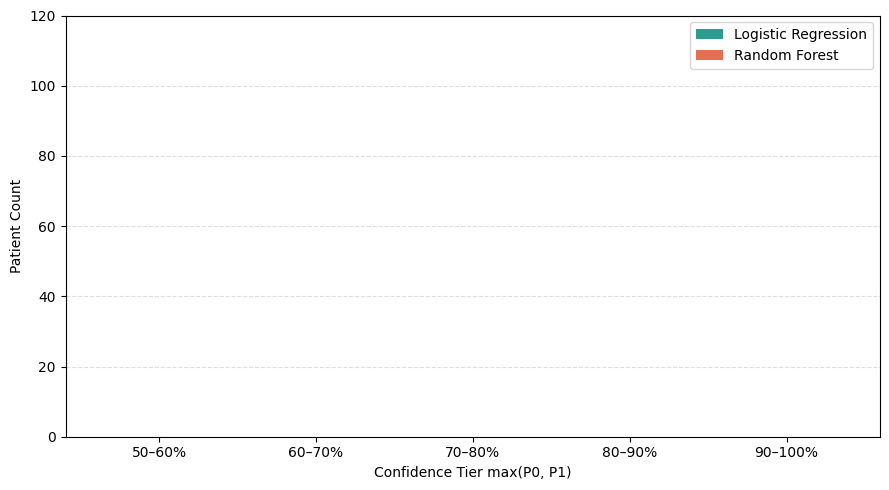

In [1]:
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_csv("heart.csv")
X = df.drop(columns=["HeartDisease"])
y = df["HeartDisease"].to_numpy()

num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, val_idx = next(skf.split(X, y))

lr_pipe = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000, random_state=42))])
rf_pipe = Pipeline([("prep", prep), ("clf", RandomForestClassifier(n_estimators=200, random_state=42))])

lr_pipe.fit(X.iloc[train_idx], y[train_idx])
rf_pipe.fit(X.iloc[train_idx], y[train_idx])


def manual_proba_both(X_df):
    X_proc = lr_pipe.named_steps["prep"].transform(X_df)
    lr = lr_pipe.named_steps["clf"]
    z = X_proc @ lr.coef_.ravel() + lr.intercept_[0]
    p1_lr = 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))
    prob_lr = np.column_stack([1.0 - p1_lr, p1_lr])

    rf = rf_pipe.named_steps["clf"]
    prob_rf = np.mean([tree.predict_proba(X_proc) for tree in rf.estimators_], axis=0)
    return prob_lr, prob_rf


X_val = X.iloc[val_idx].reset_index(drop=True)
prob_lr, prob_rf = manual_proba_both(X_val)
conf_lr = np.max(prob_lr, axis=1)
conf_rf = np.max(prob_rf, axis=1)

bins = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0001]
labels = ["50–60%", "60–70%", "70–80%", "80–90%", "90–100%"]
x = np.arange(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 5))
bars_lr = ax.bar(x - width / 2, np.zeros(len(labels)), width, label="Logistic Regression", color="#2A9D8F")
bars_rf = ax.bar(x + width / 2, np.zeros(len(labels)), width, label="Random Forest", color="#E76F51")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_xlabel("Confidence Tier max(P0, P1)")
ax.set_ylabel("Patient Count")
ax.set_ylim(0, 120)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)


def update(frame):
    step = min((frame + 1) * 8, len(X_val))
    c_lr, _ = np.histogram(conf_lr[:step], bins=bins)
    c_rf, _ = np.histogram(conf_rf[:step], bins=bins)
    for bar, h in zip(bars_lr, c_lr):
        bar.set_height(h)
    for bar, h in zip(bars_rf, c_rf):
        bar.set_height(h)
    ax.set_title(f"Streaming Confidence Distribution ({step}/{len(X_val)} Validation Patients)")
    return list(bars_lr) + list(bars_rf)


ani = animation.FuncAnimation(fig, update, frames=len(X_val) // 8 + 1, interval=150, blit=False, repeat=False)
plt.tight_layout()
plt.show()